In [6]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [83]:
# Импорт библиотек для классического ML и нейронных сетей
import pandas as pd
import numpy as np
import random

# Импорт sklearn для классических алгоритмов
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from imblearn.pipeline import Pipeline
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, HashingVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import BaseEstimator, TransformerMixin, ClassifierMixin, clone
from lightgbm import LGBMClassifier

# import for pytorch
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

# Пользовательские модули
from helper import *        # вспомогательные функции
from plots import *         # функции визуализации
from nlp import *          # функции обработки естественного языка
from transformers import * # функции для работы с трансформерами
from models import *

In [8]:
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(42)

In [9]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Используем устройство для обучения: {device}')

Используем устройство для обучения: cuda


In [10]:
df = pd.read_csv('data/data_preprocessed.csv')

Токенизация, векторизация, создание dataloader

In [ ]:
#Применяем токенизацию из nlp.py к очищенному тексту
print('Токенизация текстов с помощью tiktoken...(это может занять некоторое время)')
df['tokens'] = df['cleaned_text'].apply(tokenize_tiktoken)

Токенизация текстов с помощью tiktoken...(это может занять некоторое время)


In [17]:
#Разделение на тренировочную и валидационную выборки со стратификацией
X_train_raw, X_val_raw, y_train, y_val = train_test_split(
    df['tokens'],
    df['label'],
    test_size=0.2,
    stratify=df['label'],
    random_state=42
)

In [19]:
#Инициализация и обучение SequenceVectorizer из transformers.py
print('Векторизация последовательностей...')
vectorizer = SequenceVectorizer(max_vocab_size=20000, max_sequence_length=256)

Векторизация последовательностей...


In [20]:
X_train_vectors = vectorizer.fit_transform(X_train_raw)
X_val_vectors = vectorizer.transform(X_val_raw)

In [21]:
# Запоминаем реальный размер словаря
vocab_size = vectorizer.vocab_size_
print(f"Итоговый размер словаря: {vocab_size}")

Итоговый размер словаря: 20000


In [ ]:
# Оборачиваем числовые матрицы в Dataset из nlp.py
train_dataset = IMDBDataset(X_train_vectors, y_train)
val_dataset = IMDBDataset(X_val_vectors, y_val)

In [23]:
# Создаем DataLoader для автоматической сборки батчей
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False)

In [24]:
print(f"Данные готовы! Количество батчей в train_loader: {len(train_loader)}")

Данные готовы! Количество батчей в train_loader: 625


# 1. LGBM Baseline для сравнения

In [ ]:
#Склеиваем токены обратно в строки для TF-IDF векторизатора
X_train_text = X_train_raw.apply(lambda tokens: " ".join(tokens))
X_val_text = X_val_raw.apply(lambda tokens: " ".join(tokens))

In [54]:
print("Сборка признаков TF-IDF...")
tfidf = TfidfVectorizer(max_features=10000, stop_words='english')

Сборка признаков TF-IDF...


In [55]:
X_train_tfidf = tfidf.fit_transform(X_train_text)
X_val_tfidf = tfidf.transform(X_val_text)

In [58]:
# Создаем и обучаем модель LightGBM
print("Обучение модели LGBMClassifier... ")
model_lgbm = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.05,
    random_state=42,
    n_jobs=-1 
)
model_lgbm.fit(X_train_tfidf, y_train)

Обучение модели LGBMClassifier... 
[LightGBM] [Info] Number of positive: 20000, number of negative: 20000
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 1.275639 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 813158
[LightGBM] [Info] Number of data points in the train set: 40000, number of used features: 9997
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


,learning_rate,0.05
,n_estimators,200
,random_state,42
,n_jobs,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0


In [63]:
y_pred_lgbm = model_lgbm.predict(X_val_tfidf)
y_probs_lgbm = model_lgbm.predict_proba(X_val_tfidf)[:, 1]

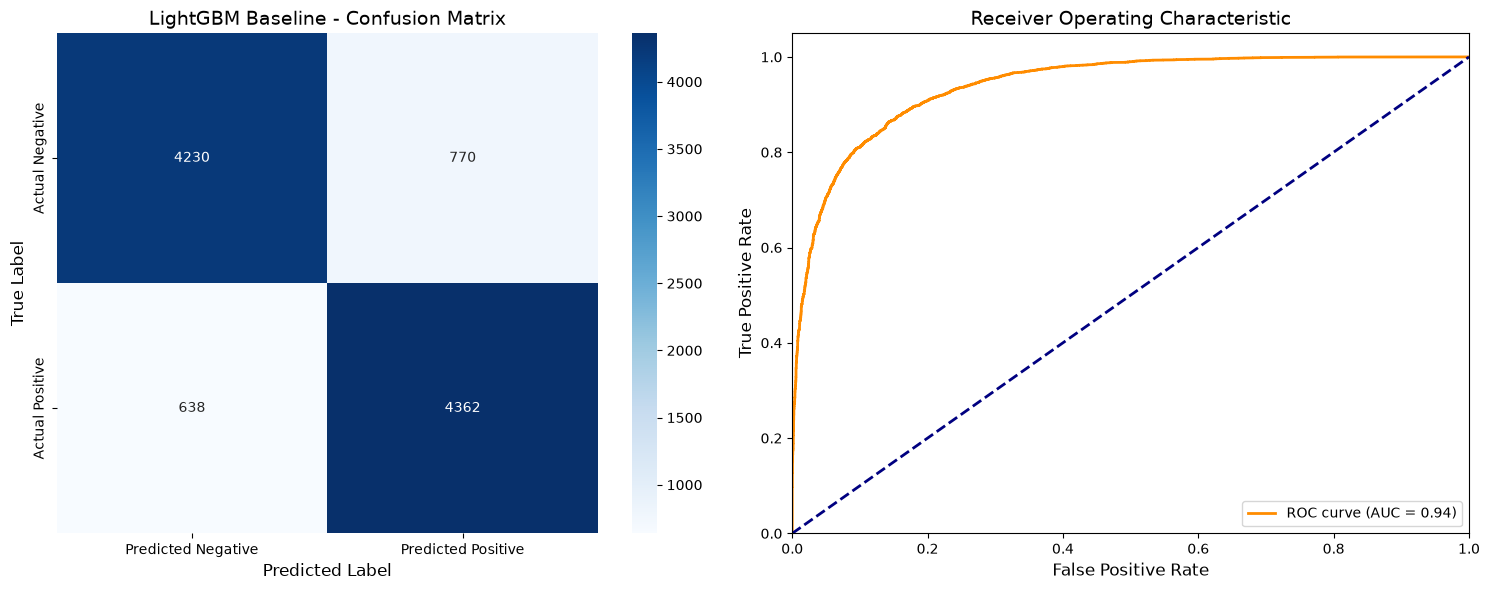


                LIGHTGBM BASELINE EVALUATION                

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9396
 F1 Score 0.8592
Precision 0.8595
   Recall 0.8592
 Accuracy 0.8592


CLASSIFICATION REPORT:
   Class  Precision  Recall
Positive   0.849961  0.8724
Negative   0.868940  0.8460



In [64]:
#Рисуем
lgbm_metrics = evaluate_classification(
    y_test=y_val,
    y_pred=y_pred_lgbm,
    y_probs=y_probs_lgbm,
    model_name="LightGBM Baseline",
    enable_plot=True
)

# 2. Инициализация модели TextCNN

In [25]:
embedding_dim = 100# размер вектора для каждого слова
num_filters = 100# количество признаков на каждое окно свертки
filter_sizes = [3,4,5] # размеры окон

In [31]:
#Cоздаем экземпляр модели и отправляем его на GPU/CPU (device)
model_cnn = TextCNNClassifier(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    num_filters=num_filters,
    filter_sizes=filter_sizes,
    output_dim=1,
    dropout=0.5
).to(device)

In [32]:
# Функция потерь для бинарной классификации логитов (0 или 1)
criterion = nn.BCEWithLogitsLoss()

In [33]:
optimizer = optim.Adam(model_cnn.parameters(), lr=1e-3)
print(model_cnn)

TextCNNClassifier(
  (embedding): Embedding(20000, 100, padding_idx=0)
  (convs): ModuleList(
    (0): Conv2d(1, 100, kernel_size=(3, 100), stride=(1, 1))
    (1): Conv2d(1, 100, kernel_size=(4, 100), stride=(1, 1))
    (2): Conv2d(1, 100, kernel_size=(5, 100), stride=(1, 1))
  )
  (fc): Linear(in_features=300, out_features=1, bias=True)
  (dropout): Dropout(p=0.5, inplace=False)
)


### 2.1 Цикл обучения

In [34]:
epochs = 5

In [36]:
print(f"Начинаем обучение модели на устройстве: {device}\n")

for epoch in range(epochs):
    train_loss, train_acc = train_pytorch_epoch(
        model=model_cnn,
        dataloader=train_loader,
        optimizer=optimizer,
        criterion=criterion,
        device=device
    )
    print(f"Эпоха [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")

print("\nОбучение завершено!")

Начинаем обучение модели на устройстве: cuda

Эпоха [1/5] | Train Loss: 0.2063 | Train Acc: 0.9177
Эпоха [2/5] | Train Loss: 0.1756 | Train Acc: 0.9307
Эпоха [3/5] | Train Loss: 0.1398 | Train Acc: 0.9461
Эпоха [4/5] | Train Loss: 0.1101 | Train Acc: 0.9582
Эпоха [5/5] | Train Loss: 0.0833 | Train Acc: 0.9686

Обучение завершено!


### 2.2 Валидация и графики

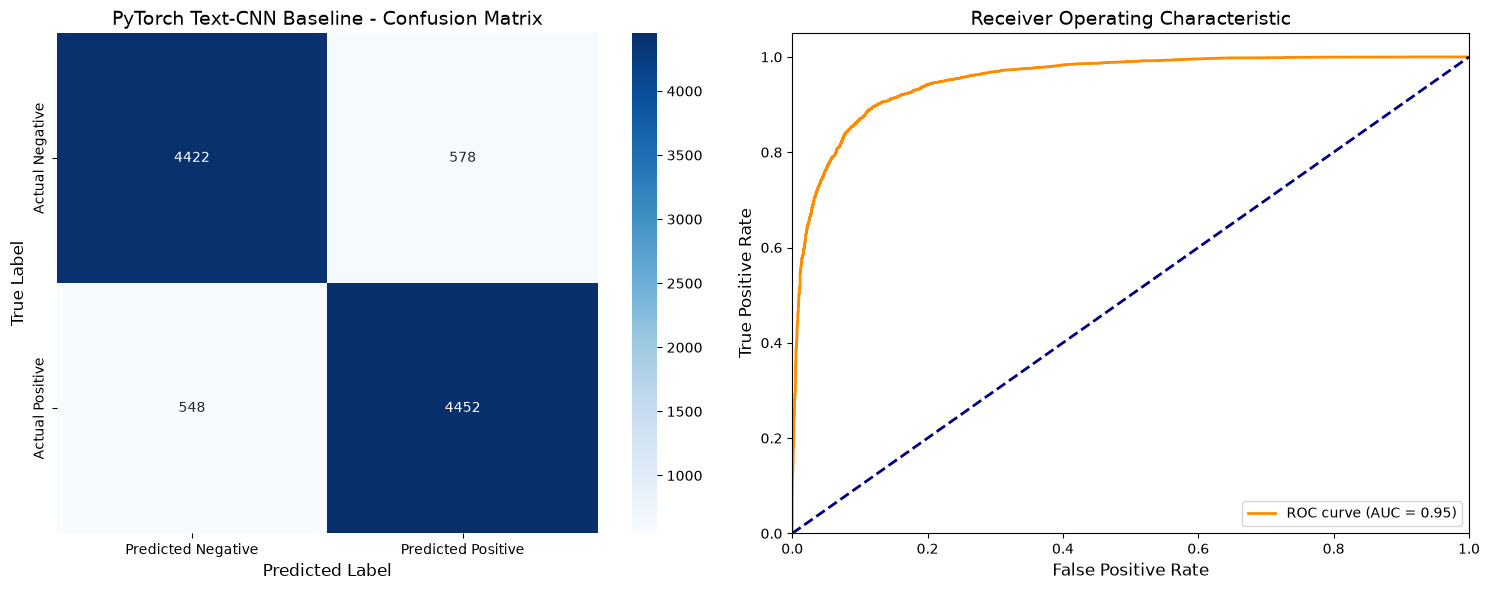


            PYTORCH TEXT-CNN BASELINE EVALUATION            

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9534
 F1 Score 0.8874
Precision 0.8874
   Recall 0.8874
 Accuracy 0.8874


CLASSIFICATION REPORT:
   Class  Precision  Recall
Positive   0.885089  0.8904
Negative   0.889738  0.8844


Итоговые числовые метики:
{'ROC AUC': 0.9534197999999998, 'F1 Score': 0.8873989865908793, 'Precision': 0.8874139469020885, 'Recall': 0.8874, 'Accuracy': 0.8874}


In [37]:
#Запускаем встроенную в helper.py функцию оценки для PyTorch
cnn_metrics = evaluate_pytorch_model(
    model=model_cnn,
    dataloader=val_loader,
    device=device,
    model_name="PyTorch Text-CNN Baseline",
    enable_plot=True
)
print("\nИтоговые числовые метики:")
print(cnn_metrics.get_numeric_metrics())

# 3. Инициализация модели RNN

In [66]:
hidden_dim = 128
embedding_dim = 100

In [69]:
model_rnn = RNNClassifier(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    num_layers=1,
    output_dim=1,
    dropout=0.3
).to(device)

In [70]:
criterion_rnn = nn.BCEWithLogitsLoss()
optimizer_rnn = optim.Adam(model_rnn.parameters(), lr=1e-3)

In [77]:
epochs = 5

### 3.1 Цикл обучения

In [78]:
print(f"Начинаем обучение модели Vanilla RNN на устройстве: {device}\n")

for epoch in range(epochs):
    train_loss, train_acc = train_pytorch_epoch(
        model=model_rnn, 
        dataloader=train_loader, 
        optimizer=optimizer_rnn, 
        criterion=criterion_rnn, 
        device=device
    )
    print(f"Эпоха [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")

print("\nОбучение RNN завершено!")

Начинаем обучение модели Vanilla RNN на устройстве: cuda

Эпоха [1/5] | Train Loss: 0.5470 | Train Acc: 0.7159
Эпоха [2/5] | Train Loss: 0.5224 | Train Acc: 0.7416
Эпоха [3/5] | Train Loss: 0.5368 | Train Acc: 0.7257
Эпоха [4/5] | Train Loss: 0.5098 | Train Acc: 0.7490
Эпоха [5/5] | Train Loss: 0.4885 | Train Acc: 0.7717

Обучение RNN завершено!


### 3.2 Валидация и графики

Запуск валидации для Vanilla RNN...


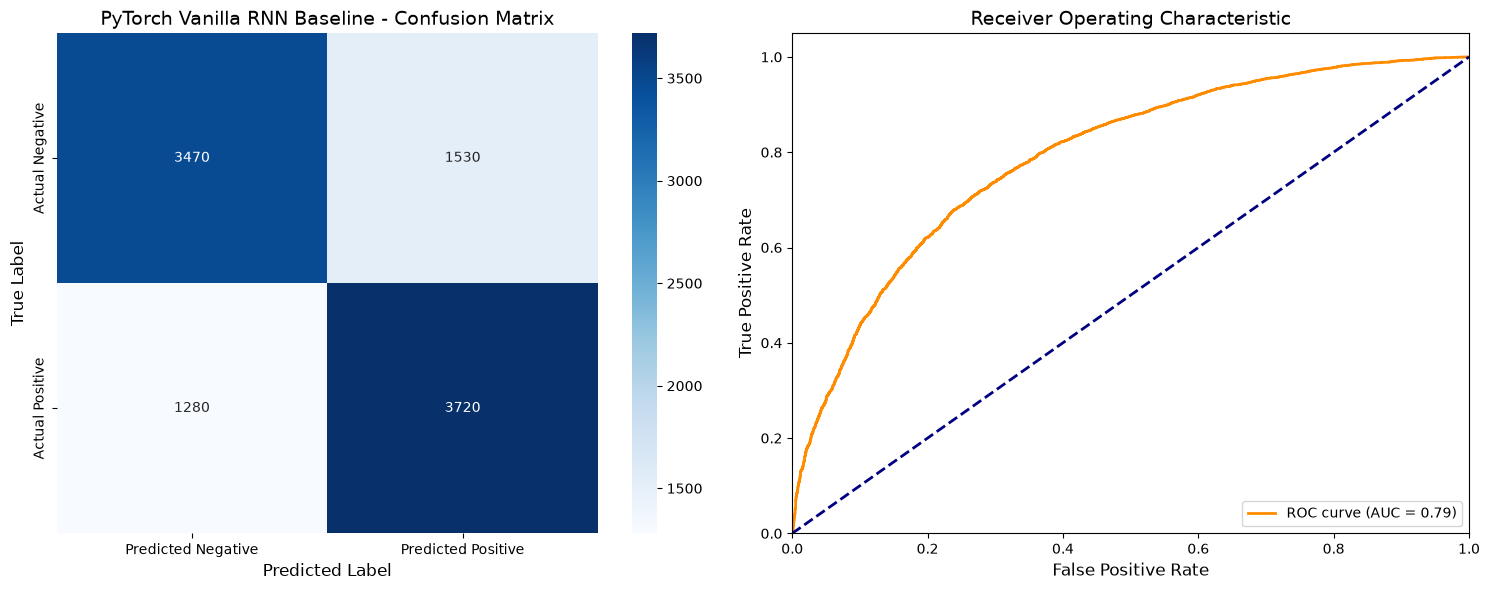


          PYTORCH VANILLA RNN BASELINE EVALUATION           

MAIN METRICS:
   Metric  Value
  ROC AUC 0.7905
 F1 Score 0.7188
Precision 0.7195
   Recall 0.7190
 Accuracy 0.7190


CLASSIFICATION REPORT:
   Class  Precision  Recall
Positive   0.708571   0.744
Negative   0.730526   0.694



In [79]:
print("Запуск валидации для Vanilla RNN...")
rnn_metrics = evaluate_pytorch_model(
    model=model_rnn,
    dataloader=val_loader,
    device=device,
    model_name="PyTorch Vanilla RNN Baseline",
    enable_plot=True
)

# 4. Инициализация модели LSTM

In [38]:
hidden_dim=128
embedding_dim = 100

In [39]:
model_lstm = LSTMClassifier(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    hidden_dim=hidden_dim,
    num_layers=1,
    output_dim=1,
    dropout=0.3
).to(device)

In [40]:
criterion_lstm = nn.BCEWithLogitsLoss()
optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=1e-3)

### 4.1 Цикл обучения

In [41]:
epochs = 5

In [42]:
print(f"Начинаем обучение модели LSTM на устройстве: {device}\n")

for epoch in range(epochs):
    train_loss, train_acc = train_pytorch_epoch(
        model=model_lstm, 
        dataloader=train_loader, 
        optimizer=optimizer_lstm, 
        criterion=criterion_lstm, 
        device=device
    )
    print(f"Эпоха [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")

print("\nОбучение LSTM завершено!")

Начинаем обучение модели LSTM на устройстве: cuda

Эпоха [1/5] | Train Loss: 0.6049 | Train Acc: 0.6591
Эпоха [2/5] | Train Loss: 0.4761 | Train Acc: 0.7782
Эпоха [3/5] | Train Loss: 0.4537 | Train Acc: 0.7888
Эпоха [4/5] | Train Loss: 0.4181 | Train Acc: 0.8153
Эпоха [5/5] | Train Loss: 0.3485 | Train Acc: 0.8552

Обучение LSTM завершено!


### 4.2 Валидация и графики

Запуск валидации для LSTM...


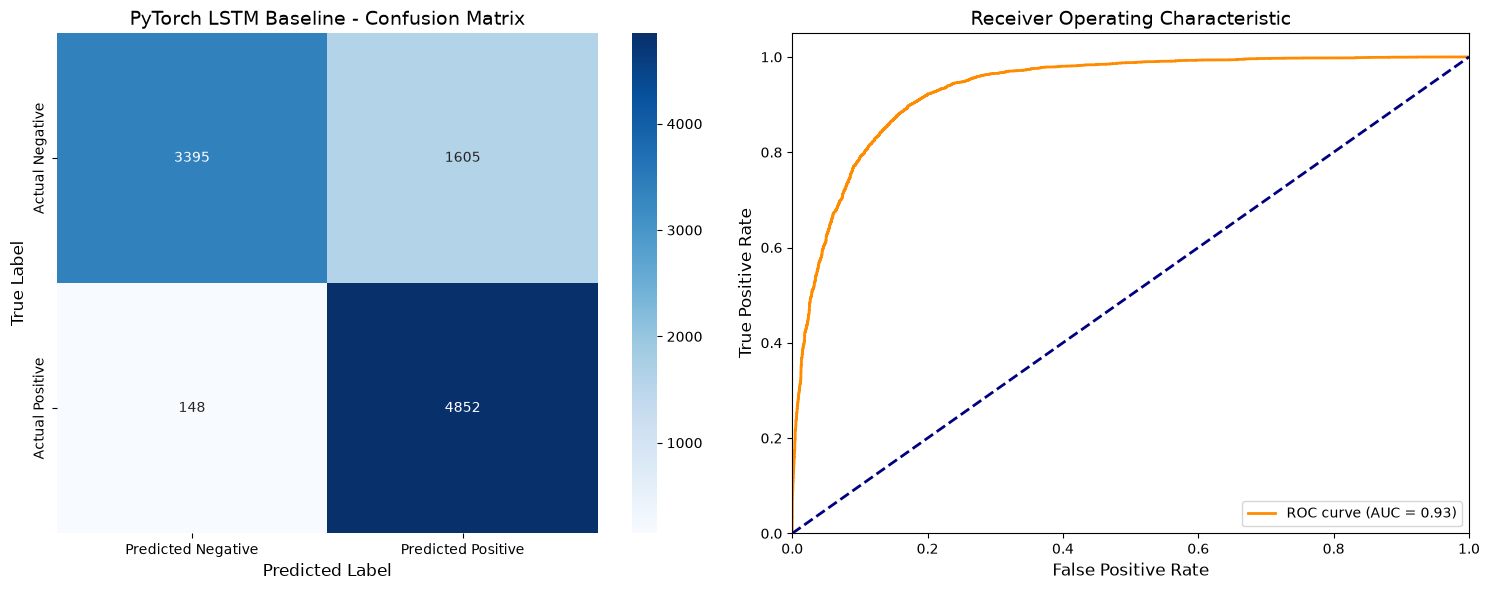


              PYTORCH LSTM BASELINE EVALUATION              

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9324
 F1 Score 0.8209
Precision 0.8548
   Recall 0.8247
 Accuracy 0.8247


CLASSIFICATION REPORT:
   Class  Precision  Recall
Positive   0.751433  0.9704
Negative   0.958227  0.6790



In [49]:
# Валидация модели LSTM
print("Запуск валидации для LSTM...")
lstm_metrics = evaluate_pytorch_model(
    model=model_lstm,
    dataloader=val_loader,
    device=device,
    model_name="PyTorch LSTM Baseline",
    enable_plot=True
)

# 5. Инициализация модели  TEXT-CNN с векторами GLOVE

In [84]:
glove_path = "data/glove.6B.100d.txt" 

In [85]:
embedding_matrix = load_glove_embeddings(
    glove_file_path=glove_path,
    token_to_id=vectorizer.token_to_id_,
    embedding_dim=100
)

Парсинг файла GloVe: data/glove.6B.100d.txt...
Матрица эмбеддингов GloVe успешно собрана!


In [86]:
model_glove_cnn = GloVeTextCNNClassifier(
    embedding_matrix=embedding_matrix,
    num_filters=100,
    filter_sizes=[3, 4, 5],
    output_dim=1,
    dropout=0.5,
    freeze=True # Замораживаем веса слов, обучаем только сверточные слои
).to(device)

In [87]:
criterion_glove = nn.BCEWithLogitsLoss()
optimizer_glove = optim.Adam(model_glove_cnn.parameters(), lr=1e-3)

### 5.1 Цикл обучения

In [88]:
epochs = 5
print(f"\nНачинаем обучение GloVe + Text-CNN на устройстве: {device}\n")

for epoch in range(epochs):
    train_loss, train_acc = train_pytorch_epoch(
        model=model_glove_cnn, 
        dataloader=train_loader, 
        optimizer=optimizer_glove, 
        criterion=criterion_glove, 
        device=device
    )
    print(f"Эпоха [{epoch+1}/{epochs}] | Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.4f}")



Начинаем обучение GloVe + Text-CNN на устройстве: cuda

Эпоха [1/5] | Train Loss: 0.5041 | Train Acc: 0.7430
Эпоха [2/5] | Train Loss: 0.3879 | Train Acc: 0.8248
Эпоха [3/5] | Train Loss: 0.3467 | Train Acc: 0.8486
Эпоха [4/5] | Train Loss: 0.3191 | Train Acc: 0.8636
Эпоха [5/5] | Train Loss: 0.2939 | Train Acc: 0.8745


### 5.2 Валидация и графики

Запуск валидации для GloVe + Text-CNN...


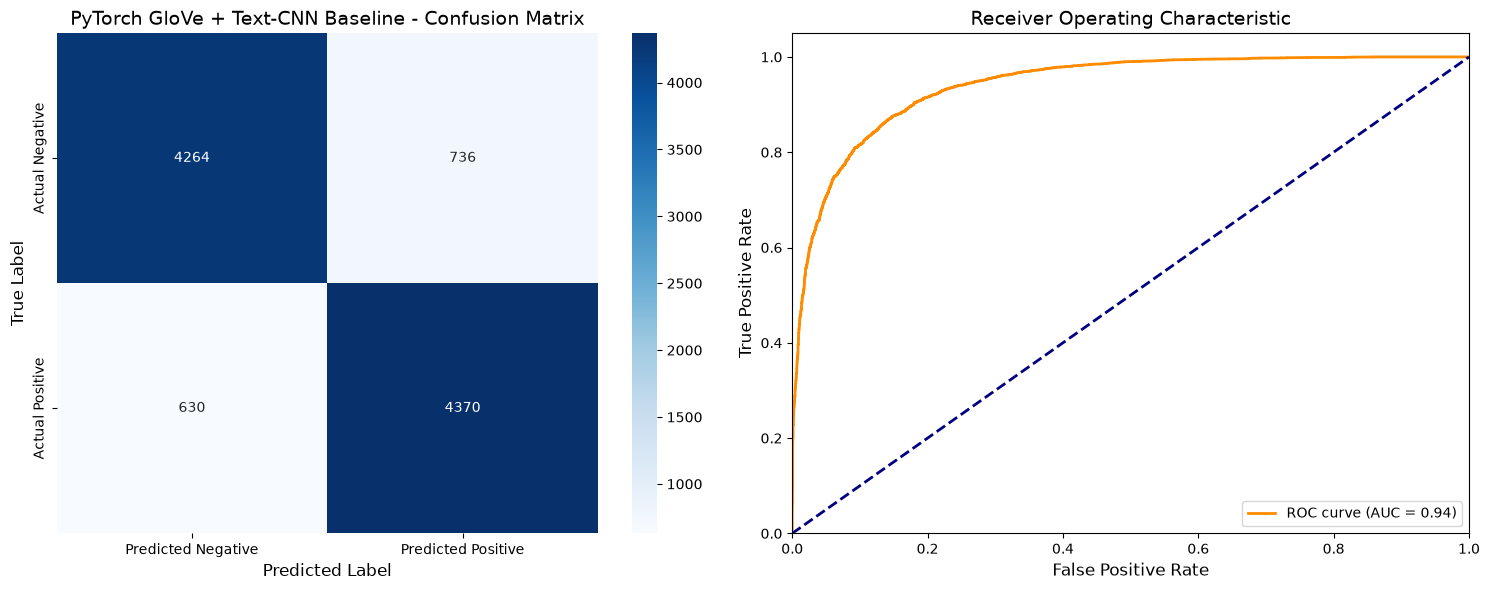


        PYTORCH GLOVE + TEXT-CNN BASELINE EVALUATION        

MAIN METRICS:
   Metric  Value
  ROC AUC 0.9409
 F1 Score 0.8634
Precision 0.8636
   Recall 0.8634
 Accuracy 0.8634


CLASSIFICATION REPORT:
   Class  Precision  Recall
Positive   0.855856  0.8740
Negative   0.871271  0.8528



In [89]:
print("Запуск валидации для GloVe + Text-CNN...")
glove_cnn_metrics = evaluate_pytorch_model(
    model=model_glove_cnn,
    dataloader=val_loader,
    device=device,
    model_name="PyTorch GloVe + Text-CNN Baseline",
    enable_plot=True
)

# Сравнительный хитмап моделей


Построение сравнительного хитмапа моделей:


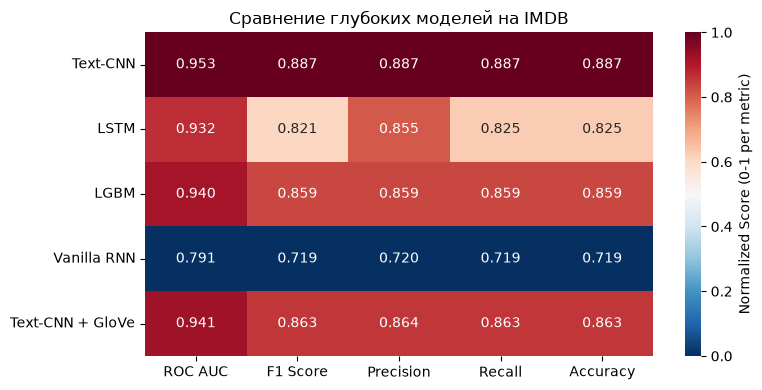

In [90]:
cnn_metrics.name = "Text-CNN"
lstm_metrics.name = "LSTM"
lgbm_metrics.name = "LGBM"
rnn_metrics.name = "Vanilla RNN"
glove_cnn_metrics.name = "Text-CNN + GloVe"
print("\nПостроение сравнительного хитмапа моделей:")
plot_metrics_heatmap(metrics=[cnn_metrics, lstm_metrics, lgbm_metrics, rnn_metrics, glove_cnn_metrics], title="Сравнение глубоких моделей на IMDB")

### Резюме по Neural Networks

В ходе экспериментов были обучены и протестированы 4 различные нейросетевые архитектуры на фреймворке PyTorch, а также классический градиентный бустинг LightGBM в качестве бейзлайна:

1. **Text-CNN (С нуля) — Абсолютный победитель**:
   * **Accuracy:** 88.7% | **ROC AUC:** 0.953
   * Параллельные свертки с разным размером окон (3, 4, 5 слов) идеально вылавливают триггерные N-граммы и устойчивые словосочетания,
   * характерные для эмоциональных отзывов. Она обучается быстрее всех дает наилучший результат.

2. **Text-CNN + GloVe — Высокая стабильность**:
   * **Accuracy:** 86.3% | **ROC AUC:** 0.941
   * Использование предобученных статических векторов GloVe дает хорошую базу, но жесткая заморозка весов не позволила модели
      адаптироваться под специфический сленг киноотзывов так же эффективно, как при обучении эмбеддингов с нуля.

3. **LGBM (TF-IDF) — Лучший классический метод**:
   * **Accuracy:** 85.9% | **ROC AUC:** 0.940
   * Показывает очень сильный результат для табличного метода. Он уступает сверточной сети, но значительно опережает рекуррентные подходы на 5 эпохах.

4. **LSTM — Перспективная, но медленная**:
   * **Accuracy:** 82.5% | **ROC AUC:** 0.932
   * Архитектура учитывает последовательный порядок слов, но требует значительно больше эпох для сходимости. На 5 эпохах она только начинает нащупывать долгосрочные зависимости.

5. ** RNN — Аутсайдер**:
   * **Accuracy:** 71.9% | **ROC AUC:** 0.791
   * Показала слабую способность к обучению на длинных последовательностях из-за классической проблемы затухания градиентов (Vanishing Gradient).